# **Lab 8 - Edge Detection (Solution)**

**Student ID:** 2240002024

**Objective:** Apply and compare edge detection methods using Python and OpenCV, and investigate how parameter changes affect the detected edges.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# New image (not the kid1.jpg used in the original notebook)
imgFile = 'images/Butterfly.jpg'

img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print('Image size:', img.shape)

Image size: (532, 800, 3)


## **Task 1: Apply Edge Detection Methods**

### Sobel Edge Detector

In [2]:
# Blur first to reduce noise, then take the derivative in x and y
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

# Magnitude = sqrt(Gx^2 + Gy^2)
sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_final = np.uint8(np.clip(sobel_combined, 0, 255))

### Prewitt Edge Detector

In [3]:
# Prewitt kernels (same idea as Sobel but without the extra weight in the middle row/column)
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_final = np.uint8(np.clip(prewitt_combined, 0, 255))

### Canny Edge Detector

In [4]:
# Canny has its own smoothing + non-maximum suppression + hysteresis thresholding
canny_edges = cv2.Canny(gray, 100, 200)

### Display the original image and the three edge maps

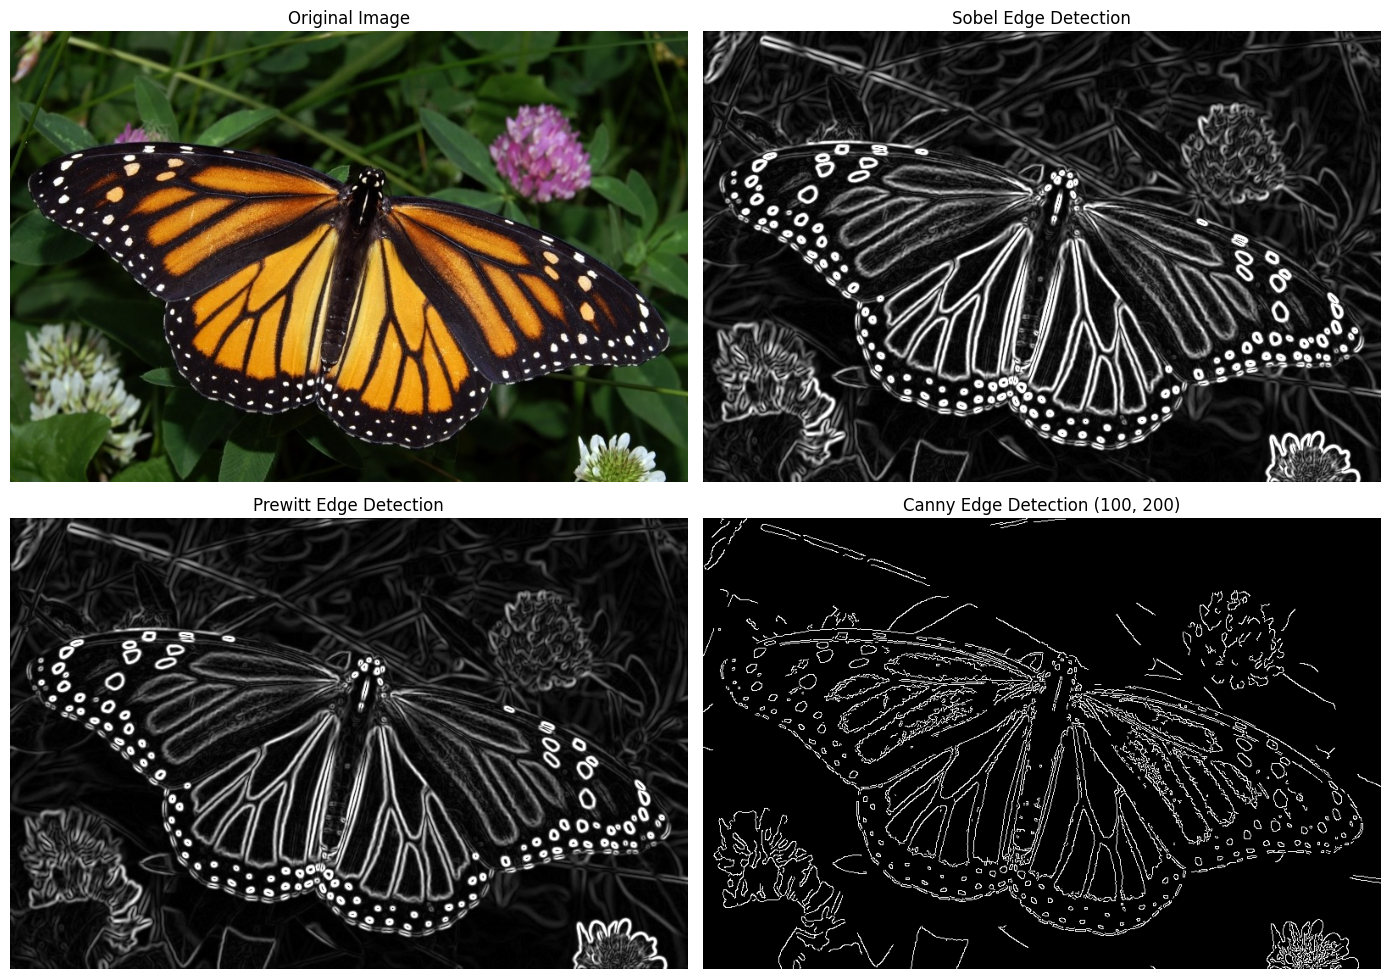

In [5]:
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image'), plt.axis('off')
plt.subplot(2, 2, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel Edge Detection'), plt.axis('off')
plt.subplot(2, 2, 3), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt Edge Detection'), plt.axis('off')
plt.subplot(2, 2, 4), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny Edge Detection (100, 200)'), plt.axis('off')
plt.tight_layout()
plt.savefig('results/task1_result.png', dpi=110, bbox_inches='tight')
plt.show()

### Comparison (Task 1)

- **Sobel:** gives thick, bright edges. The wing outlines and the veins are clear, and because of the extra weight (2) in the middle of the kernel it is a bit less sensitive to noise.
- **Prewitt:** looks very similar to Sobel but the edges are slightly weaker/darker, since all rows of the kernel have the same weight. It is a little more affected by noise.
- **Canny:** gives thin (1 pixel), clean, binary edges. It removes weak noisy responses and connects the real edges, so it gives the clearest edge map of the three.

## **Task 2: Investigate the Effect of Canny Thresholds**

Low = 30, High = 90  -->  edge pixels = 53410
Low = 50, High = 150  -->  edge pixels = 38430
Low = 100, High = 200  -->  edge pixels = 26682


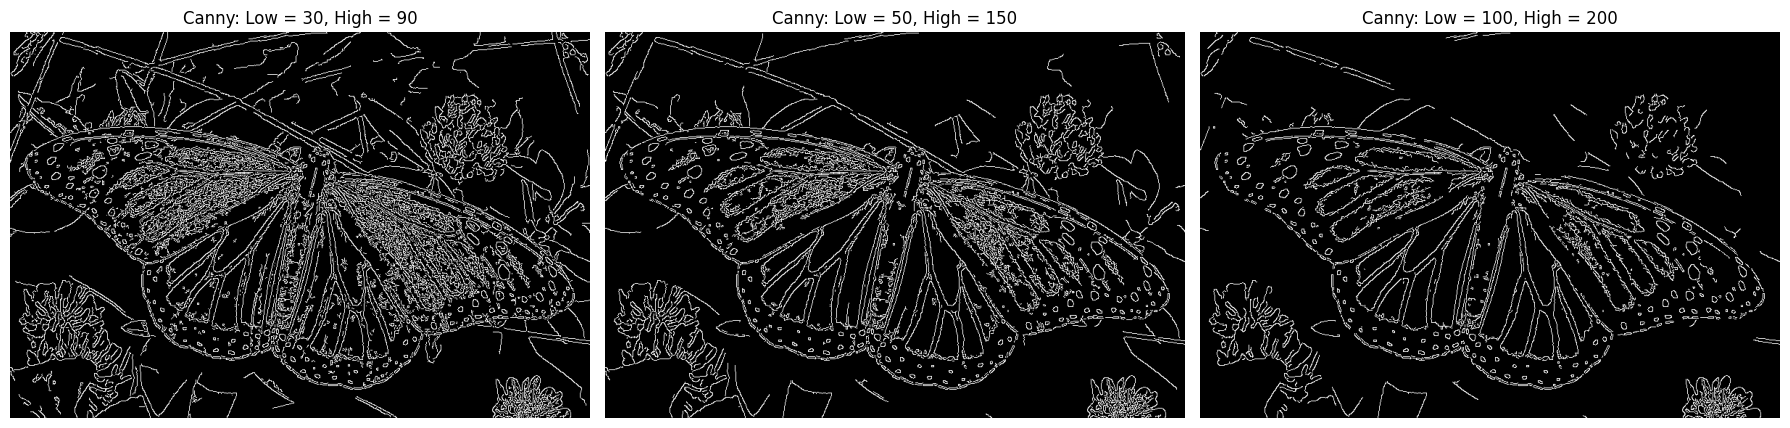

In [6]:
thresholds = [(30, 90), (50, 150), (100, 200)]

plt.figure(figsize=(18, 6))
for i, (low, high) in enumerate(thresholds):
    edges = cv2.Canny(gray, low, high)
    n_edges = np.count_nonzero(edges)
    print(f'Low = {low}, High = {high}  -->  edge pixels = {n_edges}')
    plt.subplot(1, 3, i + 1)
    plt.imshow(edges, cmap='gray')
    plt.title(f'Canny: Low = {low}, High = {high}')
    plt.axis('off')
plt.tight_layout()
plt.savefig('results/task2_result.png', dpi=110, bbox_inches='tight')
plt.show()

### Explanation (Task 2)

| Low | High | Edge pixels |
|-----|------|-------------|
| 30  | 90   | 53,410 |
| 50  | 150  | 38,430 |
| 100 | 200  | 26,682 |

In Canny, the **high threshold** decides which pixels are strong edges (always kept), and the **low threshold** decides which weak pixels are kept only if they are connected to a strong edge (hysteresis). Pixels below the low threshold are removed.

- **Low = 30, High = 90:** the thresholds are low, so even small intensity changes become edges. This gives the most edge pixels: many fine details (texture inside the wings, leaves and grass) are visible, but the result is cluttered and noisy.
- **Low = 50, High = 150:** about 28% fewer edge pixels. Most of the background texture is gone, while the wing outline, veins, spots and flowers stay clear. Good balance between detail and noise.
- **Low = 100, High = 200:** the fewest edge pixels (about half of the first case). Only the strongest edges remain; the image is clean but weak edges and small details are lost and some contours are broken.

**Conclusion:** increasing the thresholds reduces the number of detected edges. Low thresholds show more detail but also more noise; high thresholds remove noise but can also remove real weak edges. For this image, (50, 150) gives the best result.